In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import OneHotEncoder , StandardScaler
import cv2
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import datasets
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,LSTM, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score
from sklearn.model_selection import cross_val_score , GridSearchCV
from xgboost import XGBRegressor

# Plant Disease Prediction

## download data

In [3]:
!pip install kaggle

In [4]:
# configuring the path of Kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [5]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:17<00:00, 126MB/s]



In [6]:
!ls

plantvillage-dataset.zip  sample_data


In [7]:
import random
random.seed(0)
np.random.seed(0)
tf.random.set_seed(0)

In [8]:
from zipfile import ZipFile

data="/content/plantvillage-dataset.zip"

with ZipFile(data,'r') as zip:
  zip.extractall()
  print("the dataset is all extracted")

the dataset is all extracted


In [9]:
print(os.listdir("/content/plantvillage dataset"))
print(len(os.listdir("/content/plantvillage dataset/segmented")))

print(os.listdir("/content/plantvillage dataset/segmented")[0:5])

print(len(os.listdir("/content/plantvillage dataset/color/Apple___Apple_scab")),'\n')

print(len(os.listdir("/content/plantvillage dataset/color/Blueberry___healthy")),'\n')

print(os.listdir("/content/plantvillage dataset/color"))

print(len(os.listdir("/content/plantvillage dataset/color")))

['color', 'segmented', 'grayscale']
38
['Apple___Black_rot', 'Grape___healthy', 'Apple___healthy', 'Apple___Apple_scab', 'Tomato___Early_blight']
630 

1502 

['Apple___Black_rot', 'Grape___healthy', 'Apple___healthy', 'Apple___Apple_scab', 'Tomato___Early_blight', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Apple___Cedar_apple_rust', 'Potato___Late_blight', 'Grape___Black_rot', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Raspberry___healthy', 'Tomato___Target_Spot', 'Tomato___healthy', 'Peach___healthy', 'Pepper,_bell___healthy', 'Corn_(maize)___Common_rust_', 'Orange___Haunglongbing_(Citrus_greening)', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Late_blight', 'Squash___Powdery_mildew', 'Corn_(maize)___healthy', 'Cherry_(including_sour)___healthy', 'Tomato___Bacterial_spot', 'Tomato___Septoria_leaf_spot', 'Pepper,_bell___Bacterial_spot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Soybea

In [10]:
print(len(os.listdir("plantvillage dataset/color/Grape___healthy")))
print(os.listdir("plantvillage dataset/color/Grape___healthy")[:5])

423
['18fd5d50-f80c-426c-bfdb-5ca325065f24___Mt.N.V_HL 6024.JPG', '61a531ba-3d52-4af3-8828-c2dbba4d3b1d___Mt.N.V_HL 8941.JPG', 'ef0cd637-5b34-489e-affc-72cce3dbc901___Mt.N.V_HL 6138.JPG', '7c10d5ab-f960-4fa6-a965-8c825df24810___Mt.N.V_HL 9041.JPG', '8fc498ea-cad4-48cd-9fea-af07f803a63b___Mt.N.V_HL 6198.JPG']


## image preprocess

(256, 256, 3)


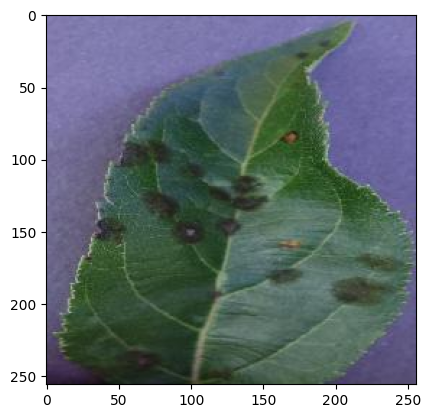

In [11]:
img_path = '/content/plantvillage dataset/color/Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG'

image = mpimg.imread(img_path)
print(image.shape)

plt.imshow(image)
plt.show()

In [12]:
base_dir ='/content/plantvillage dataset/color'

In [13]:
#image parameters
img_size = 224
batch_size =32

In [14]:
data_gen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [15]:
# generate train data
train_gen = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size,img_size),
    batch_size=batch_size,
    subset='training',
    class_mode='categorical'
)

Found 43456 images belonging to 38 classes.


In [16]:
# generate validation data
validation_gen = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode='categorical',
    shuffle=False
)

Found 10849 images belonging to 38 classes.


## CNN

In [17]:
model = keras.Sequential()

model.add(keras.layers.Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(64,(3,3),activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(128,(3,3),activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dropout(0.4))

model.add(keras.layers.Dense(64, activation='relu'))
model.add(keras.layers.Dropout(0.2))

model.add(keras.layers.Dense(train_gen.num_classes,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,179,686 (42.65 MB)

 Trainable params: 11,179,686 (42.65 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [20]:
# training the model
history= model.fit(
    train_gen,
    steps_per_epoch =train_gen.samples // batch_size,
    epochs=10,
    validation_data = validation_gen,
    validation_steps= validation_gen.samples // batch_size)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 155s 106ms/step - accuracy: 0.3689 - loss: 2.3102 - val_accuracy: 0.6256 - val_loss: 1.3216
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - accuracy: 0.5500 - loss: 1.5001 - val_accuracy: 0.7267 - val_loss: 0.9548
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 133s 98ms/step - accuracy: 0.6246 - loss: 1.2153 - val_accuracy: 0.7971 - val_loss: 0.7132
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 138s 101ms/step - accuracy: 0.6863 - loss: 1.0003 - val_accuracy: 0.8408 - val_loss: 0.5405
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - accuracy: 0.7251 - loss: 0.8601 - val_accuracy: 0.8463 - val_loss: 0.5296
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 139s 102ms/step - accuracy: 0.7594 - loss: 0.7495 - val_accuracy: 0.8564 - val_loss: 0.4908
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 131s 97ms/step - accuracy: 0.7842 - loss: 0.6773 - val_accuracy: 0.8590 - val_loss: 0.4494
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 97ms/step - accurac

340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 74ms/step - accuracy: 0.8887 - loss: 0.3465
Validation accuracy: 88.87%
340/340 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.730     0.643     0.684       126
                                 Apple___Black_rot      0.933     0.782     0.851       124
                          Apple___Cedar_apple_rust      0.551     0.491     0.519        55
                                   Apple___healthy      0.848     0.833     0.840       329
                               Blueberry___healthy      0.923     0.963     0.943       300
          Cherry_(including_sour)___Powdery_mildew      0.899     0.933     0.916       210
                 Cherry_(including_sour)___healthy      0.832     0.929     0.878       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.500     0.020     0.038       102
                       

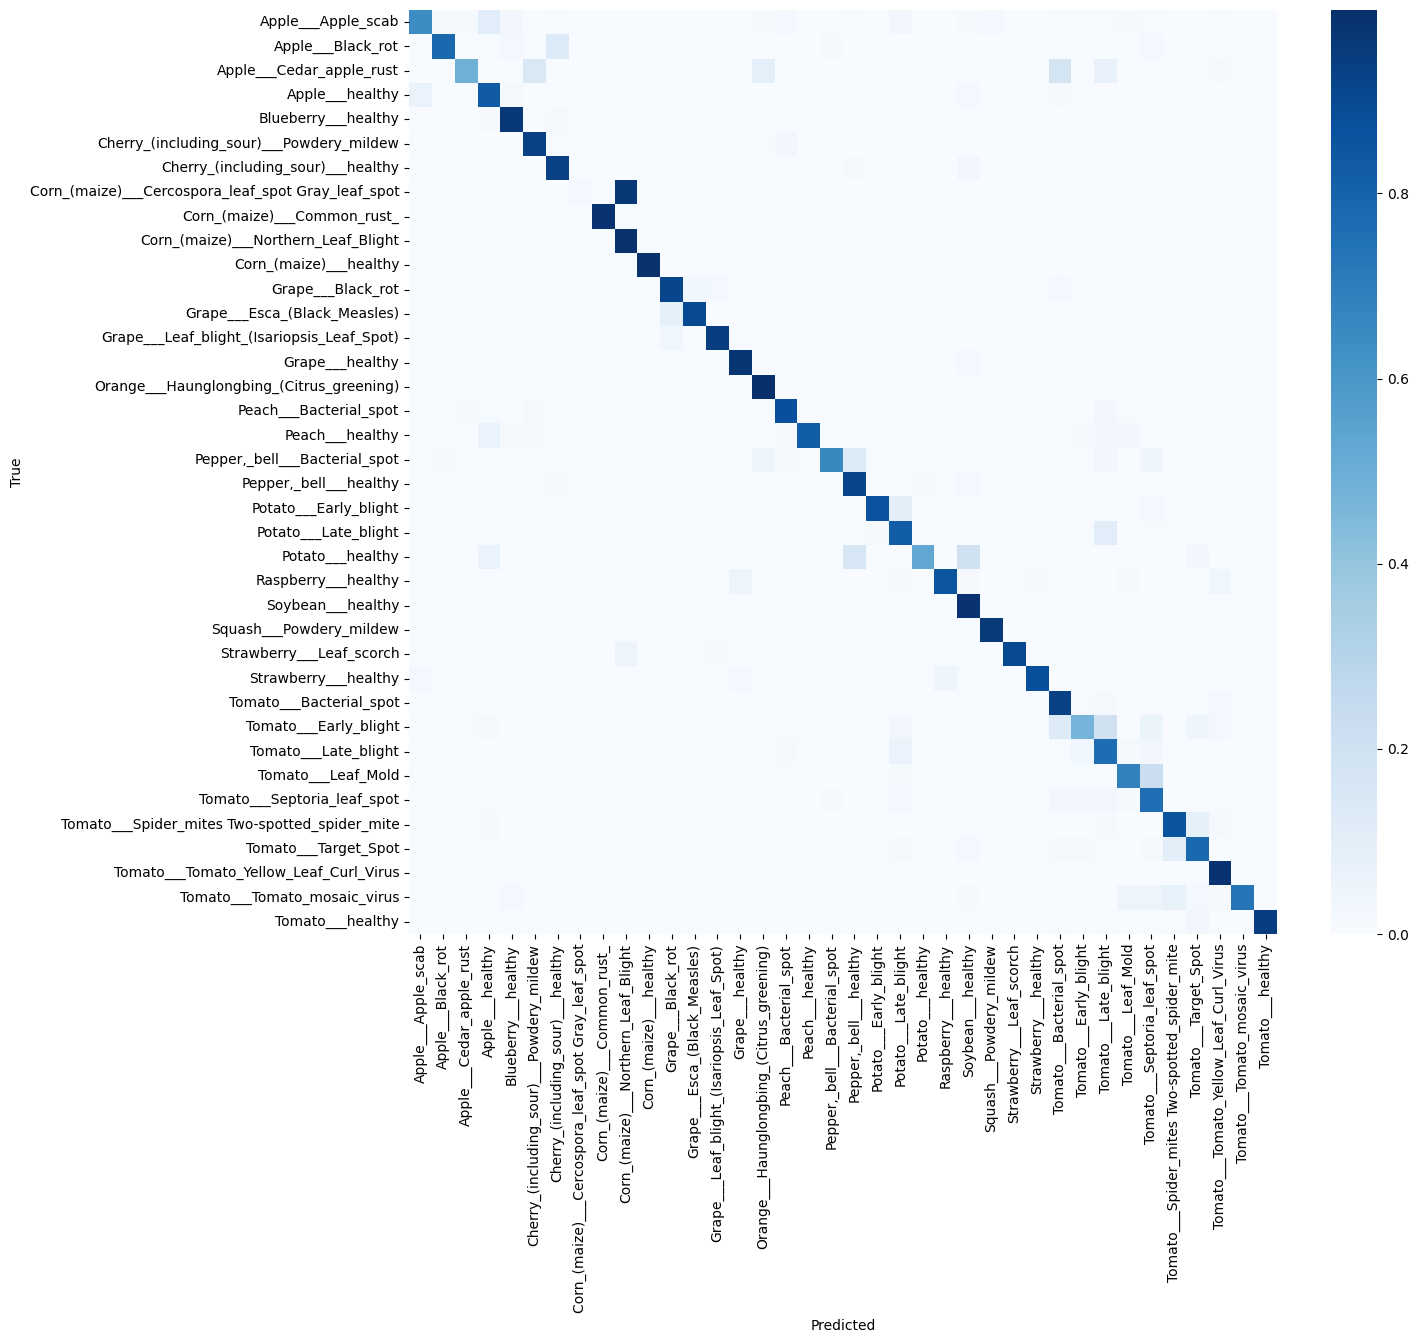

In [21]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

val_loss, val_acc = model.evaluate(validation_gen)
print(f"Validation accuracy: {val_acc*100:.2f}%")

validation_gen.reset()
probs = model.predict(validation_gen)
y_pred = np.argmax(probs, axis=1)
y_true = validation_gen.classes
labels = list(validation_gen.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=labels, digits=3))

cm = confusion_matrix(y_true, y_pred, normalize='true')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_gen, steps=validation_gen.samples // batch_size)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Evaluating model...
339/339 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.8886 - loss: 0.3465
Validation Accuracy: 88.86%


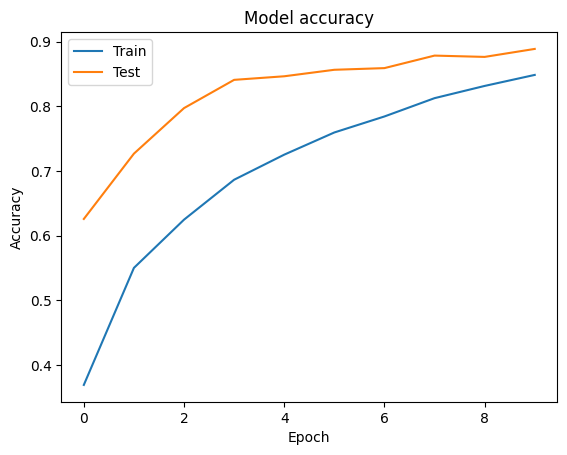

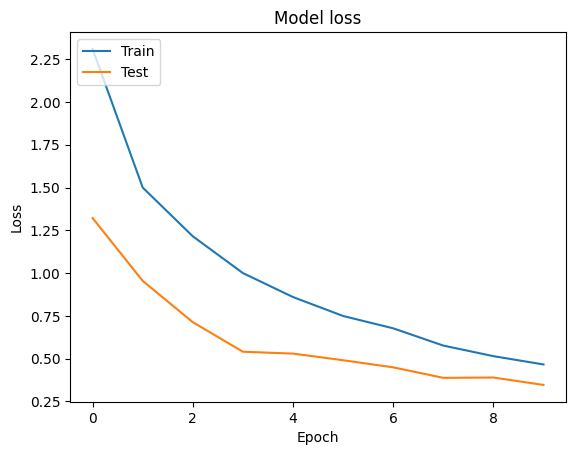

In [23]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

In [24]:
# function to load and preprocess the image
def Preprocessing(image_path, img_size=(224,224)):
  # load the image
  img = Image.open(image_path)
  # resize the image
  img = img.resize(img_size)
  #convert to numpy array
  img = np.array(img)
  # add batch dimention
  imgage = np.expand_dims(img,axis=0)
  # scale the image
  image = imgage.astype('float32')/255
  return image


In [25]:
# function to predict the class
def Prediction(model , image_path, class_indicies):
  image= Preprocessing(image_path)
  predi = model.predict(image)
  pred = np.argmax(predi,axis=1)[0]
  class_name = class_indicies[pred]
  return class_name

In [26]:
# Create a mapping from class indices to class names
class_indices = {v: k for k, v in train_gen.class_indices.items()}
class_indices

{0: 'Apple___Apple_scab',
 1: 'Apple___Black_rot',
 2: 'Apple___Cedar_apple_rust',
 3: 'Apple___healthy',
 4: 'Blueberry___healthy',
 5: 'Cherry_(including_sour)___Powdery_mildew',
 6: 'Cherry_(including_sour)___healthy',
 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 8: 'Corn_(maize)___Common_rust_',
 9: 'Corn_(maize)___Northern_Leaf_Blight',
 10: 'Corn_(maize)___healthy',
 11: 'Grape___Black_rot',
 12: 'Grape___Esca_(Black_Measles)',
 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 14: 'Grape___healthy',
 15: 'Orange___Haunglongbing_(Citrus_greening)',
 16: 'Peach___Bacterial_spot',
 17: 'Peach___healthy',
 18: 'Pepper,_bell___Bacterial_spot',
 19: 'Pepper,_bell___healthy',
 20: 'Potato___Early_blight',
 21: 'Potato___Late_blight',
 22: 'Potato___healthy',
 23: 'Raspberry___healthy',
 24: 'Soybean___healthy',
 25: 'Squash___Powdery_mildew',
 26: 'Strawberry___Leaf_scorch',
 27: 'Strawberry___healthy',
 28: 'Tomato___Bacterial_spot',
 29: 'Tomato___Early_blight',
 30: '

In [27]:
# saving the class names as json file
import json
json.dump(class_indices, open('class_indices.json', 'w'))

In [28]:
# Example Usage
image_path = '/content/plantvillage dataset/color/Apple___Black_rot/02186b4f-a9e1-4d19-ae3d-6cfb0f4b106a___JR_FrgE.S 2828.JPG'
#image_path = '/content/test_blueberry_healthy.jpg'
#image_path = '/content/test_potato_early_blight.jpg'
predicted_class_name = Prediction(model, image_path, class_indices)

# Output the result
print("Predicted Class Name:", predicted_class_name)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step
Predicted Class Name: Apple___Black_rot


## MobileNetV2

In [29]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=20, zoom_range=0.2,
    width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, vertical_flip=True)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2)

train_gen = train_datagen.flow_from_directory(
    base_dir, target_size=(224,224), batch_size=32,
    subset='training', class_mode='categorical')

validation_gen = val_datagen.flow_from_directory(
    base_dir, target_size=(224,224), batch_size=32,
    subset='validation', class_mode='categorical', shuffle=False)

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.


In [30]:
base = MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

x = keras.layers.GlobalAveragePooling2D()(base.output)
x = keras.layers.Dropout(0.3)(x)
out = keras.layers.Dense(train_gen.num_classes, activation='softmax')(x)
tl_model = keras.Model(base.input, out)

tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss='categorical_crossentropy', metrics=['accuracy'])

es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
tl_model.fit(train_gen, validation_data=validation_gen, epochs=8, callbacks=[es])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 579s 418ms/step - accuracy: 0.8160 - loss: 0.6372 - val_accuracy: 0.9029 - val_loss: 0.3128
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 527s 388ms/step - accuracy: 0.8984 - loss: 0.3156 - val_accuracy: 0.9191 - val_loss: 0.2515
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 547s 403ms/step - accuracy: 0.9064 - loss: 0.2858 - val_accuracy: 0.9251 - val_loss: 0.2314
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 546s 402ms/step - accuracy: 0.9133 - loss: 0.2628 - val_accuracy: 0.9252 - val_loss: 0.2328
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 541s 399ms/step - accuracy: 0.9142 - loss: 0.2599 - val_accuracy: 0.9334 - val_loss: 0.2050
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 521s 384ms/step - accuracy: 0.9202 - loss: 0.2476 - val_accuracy: 0.9323 - val_loss: 0.2038
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 545s 401ms/step - accuracy: 0.9201 - loss: 0.2452 - val_accuracy: 0.9296 - val_loss: 0.2115
Epoch 8/8
1358/1358 

In [31]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss='categorical_crossentropy', metrics=['accuracy'])
tl_model.fit(train_gen, validation_data=validation_gen, epochs=8, callbacks=[es])

Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 556s 398ms/step - accuracy: 0.8483 - loss: 0.5666 - val_accuracy: 0.9394 - val_loss: 0.1949
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 545s 402ms/step - accuracy: 0.9130 - loss: 0.2678 - val_accuracy: 0.9430 - val_loss: 0.1732
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 550s 405ms/step - accuracy: 0.9297 - loss: 0.2098 - val_accuracy: 0.9488 - val_loss: 0.1504
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 522s 384ms/step - accuracy: 0.9381 - loss: 0.1817 - val_accuracy: 0.9537 - val_loss: 0.1367
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 543s 400ms/step - accuracy: 0.9466 - loss: 0.1582 - val_accuracy: 0.9553 - val_loss: 0.1301
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 552s 406ms/step - accuracy: 0.9524 - loss: 0.1407 - val_accuracy: 0.9613 - val_loss: 0.1142
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 551s 406ms/step - accuracy: 0.9566 - loss: 0.1299 - val_accuracy: 0.9647 - val_loss: 0.1059
Epoch 8/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 521s 384ms/step - accuracy: 

340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.9665 - loss: 0.1009
Validation accuracy: 96.65%
340/340 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.967     0.944     0.956       126
                                 Apple___Black_rot      0.992     0.984     0.988       124
                          Apple___Cedar_apple_rust      0.982     0.982     0.982        55
                                   Apple___healthy      0.994     0.982     0.988       329
                               Blueberry___healthy      0.993     0.993     0.993       300
          Cherry_(including_sour)___Powdery_mildew      0.995     0.990     0.993       210
                 Cherry_(including_sour)___healthy      0.988     0.976     0.982       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.844     0.902     0.872       102
                       

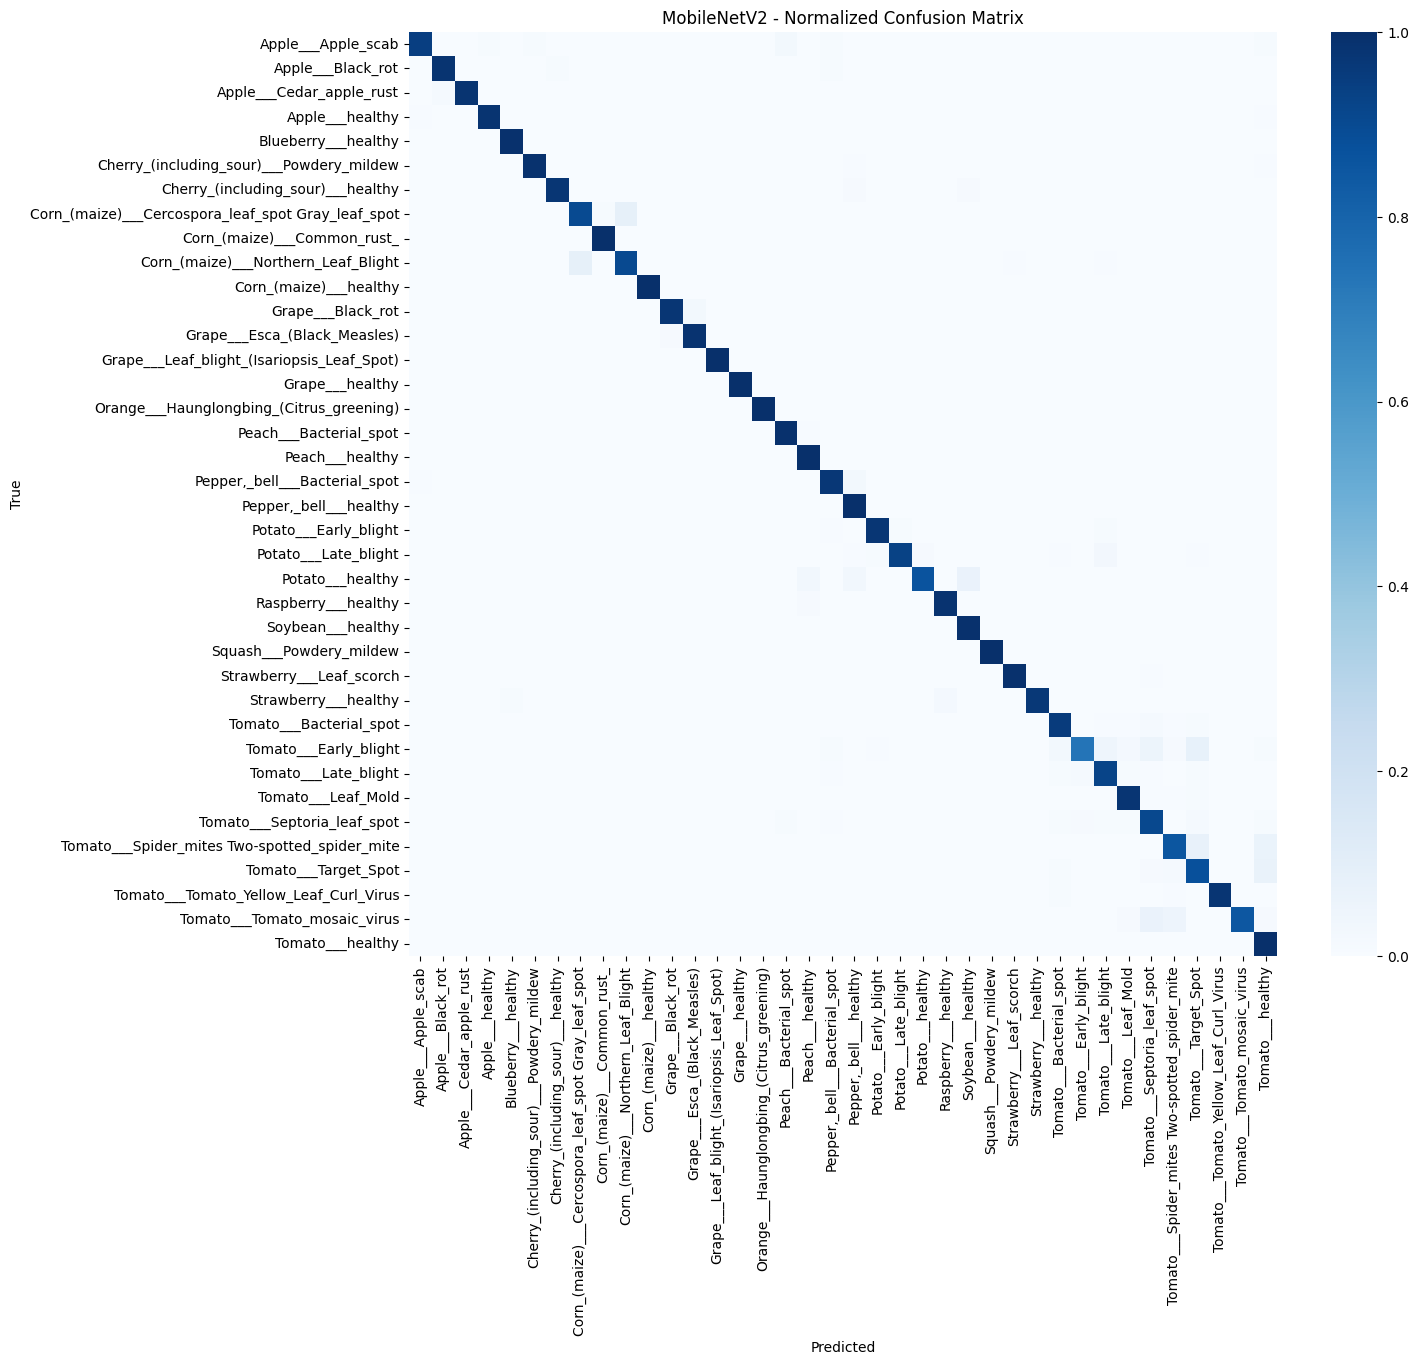

In [36]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Overall accuracy on the full validation set (no `steps`)
val_loss, val_acc = tl_model.evaluate(validation_gen)
print(f"Validation accuracy: {val_acc*100:.2f}%")

# 2. Predictions (validation_gen must have shuffle=False)
validation_gen.reset()
probs = tl_model.predict(validation_gen)
y_pred = np.argmax(probs, axis=1)
y_true = validation_gen.classes
labels = list(validation_gen.class_indices.keys())

# 3. Precision / recall / F1
print(classification_report(y_true, y_pred, target_names=labels, digits=3))

# 4. Normalized confusion matrix
cm = confusion_matrix(y_true, y_pred, normalize='true')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('MobileNetV2 - Normalized Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [35]:
# Example Usage
image_path = '/content/plantvillage dataset/segmented/Pepper,_bell___Bacterial_spot/01613cd0-d3cd-4e96-945c-a312002037bf___JR_B.Spot 3262_final_masked.jpg'
predicted_class_name = Prediction(tl_model, image_path, class_indices)

# Output the result
print("Predicted Class Name:", predicted_class_name)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
Predicted Class Name: Pepper,_bell___healthy
